<a href="https://colab.research.google.com/github/divyasethu0506-droid/divya/blob/main/Unemployment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving Unemployment in India.csv to Unemployment in India.csv


In [2]:
import pandas as pd

df = pd.read_csv('Unemployment in India.csv')

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
# Check dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (768, 7)

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ K

In [4]:
# Remove extra spaces from column names

df.columns = df.columns.str.strip()

# Remove duplicate rows

df = df.drop_duplicates()

# Remove rows with missing values

df = df.dropna()

# Reset index

df = df.reset_index(drop=True)

print("Data Cleaning Completed!")

print("Final Dataset Shape:", df.shape)

display(df.head())

Data Cleaning Completed!
Final Dataset Shape: (740, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [5]:
# Calculate average unemployment rate for each state

state_unemployment = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False)

print("State-wise Average Unemployment Rate:")
display(state_unemployment)

State-wise Average Unemployment Rate:


,Estimated Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


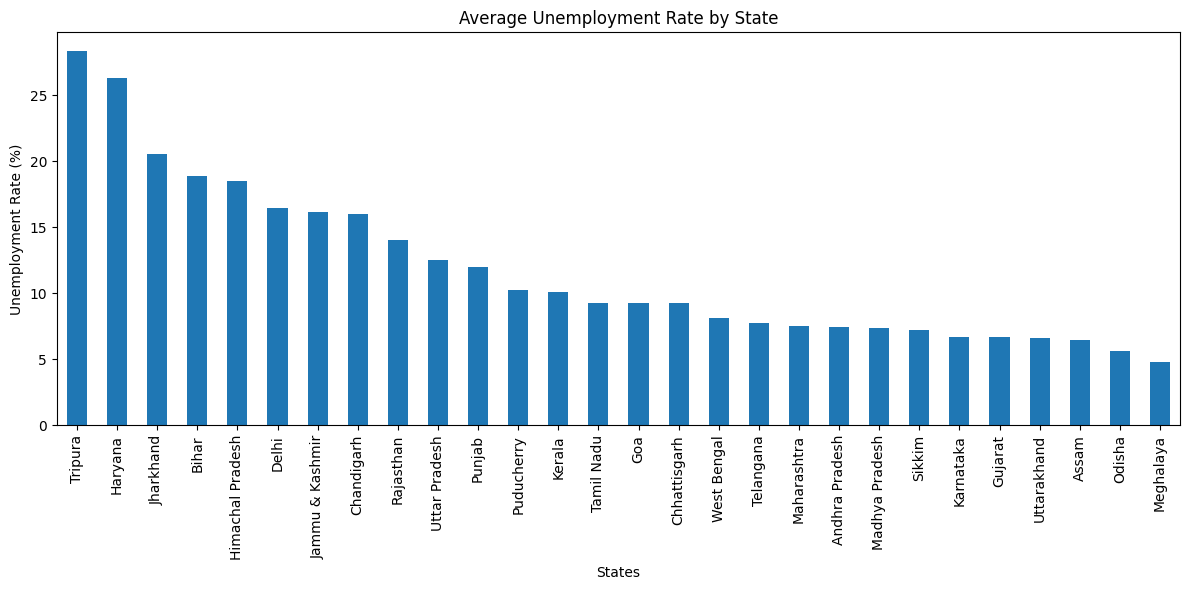

In [8]:
plt.figure(figsize=(12,6))

state_unemployment.plot(kind='bar')

plt.title('Average Unemployment Rate by State')
plt.xlabel('States')
plt.ylabel('Unemployment Rate (%)')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [9]:
# Convert Date column into datetime format

df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Extract Month and Year

df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year

# Calculate monthly average unemployment

monthly_unemployment = df.groupby(
    ['Year', 'Month']
)['Estimated Unemployment Rate (%)'].mean()

print("Monthly Average Unemployment Rate:")
display(monthly_unemployment)

Monthly Average Unemployment Rate:


Year  Month
2019  5         8.874259
      6         9.303333
      7         9.033889
      8         9.637925
      9         9.051731
      10        9.900909
      11        9.868364
      12        9.497358
2020  1         9.950755
      2         9.964717
      3        10.700577
      4        23.641569
      5        24.875294
      6        11.903600
Name: Estimated Unemployment Rate (%), dtype: float64

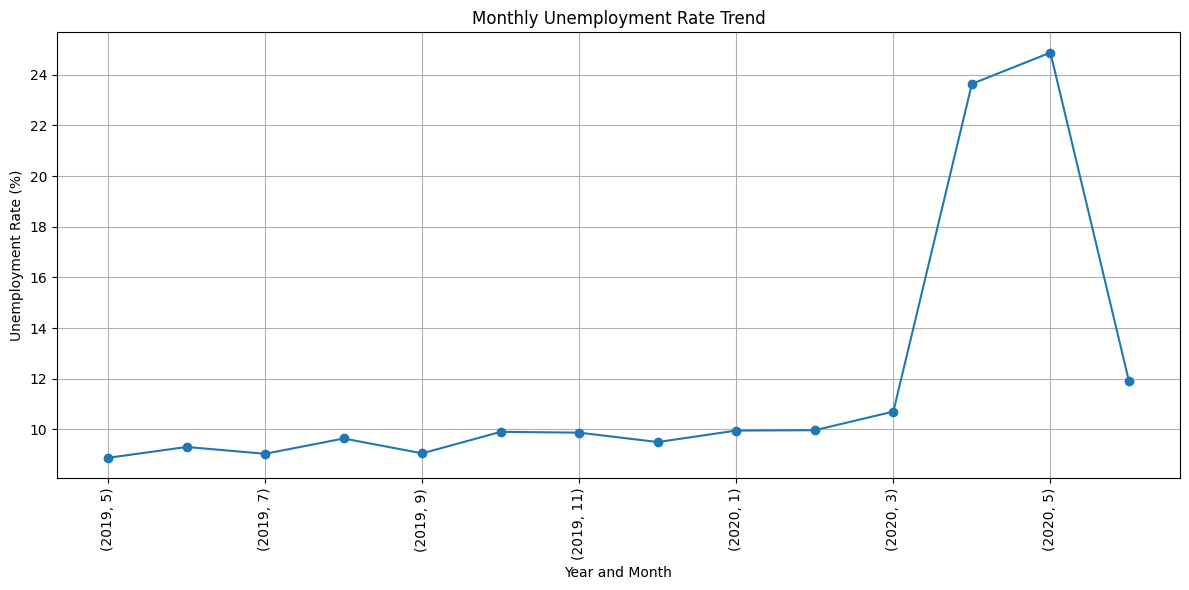

In [10]:
plt.figure(figsize=(12,6))

monthly_unemployment.plot(marker='o')

plt.title('Monthly Unemployment Rate Trend')
plt.xlabel('Year and Month')
plt.ylabel('Unemployment Rate (%)')

plt.xticks(rotation=90)
plt.grid()
plt.tight_layout()
plt.show()

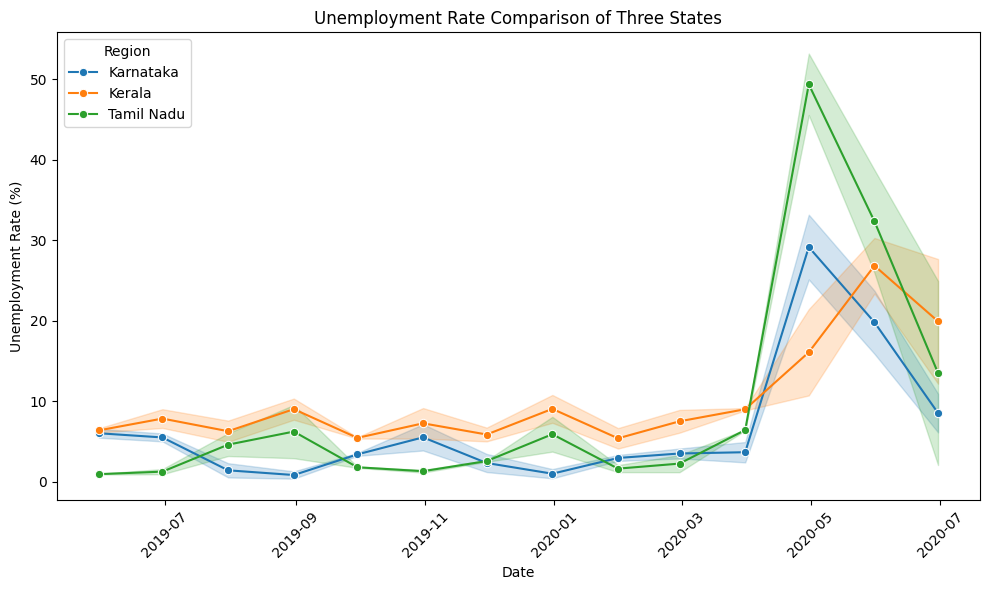

In [11]:
# Select three states

selected_states = ['Tamil Nadu', 'Kerala', 'Karnataka']

# Filter selected states

state_data = df[df['Region'].isin(selected_states)]

# Plot unemployment trends

plt.figure(figsize=(10,6))

sns.lineplot(
    data=state_data,
    x='Date',
    y='Estimated Unemployment Rate (%)',
    hue='Region',
    marker='o'
)

plt.title('Unemployment Rate Comparison of Three States')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

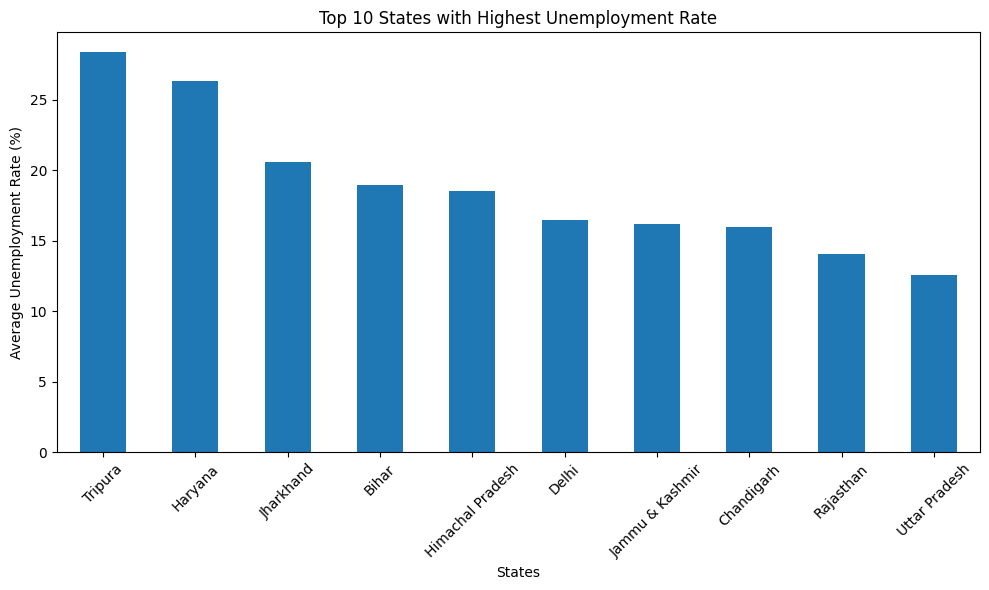

In [12]:
# Find top 10 states with highest unemployment

top_10 = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))

top_10.plot(kind='bar')

plt.title('Top 10 States with Highest Unemployment Rate')
plt.xlabel('States')
plt.ylabel('Average Unemployment Rate (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

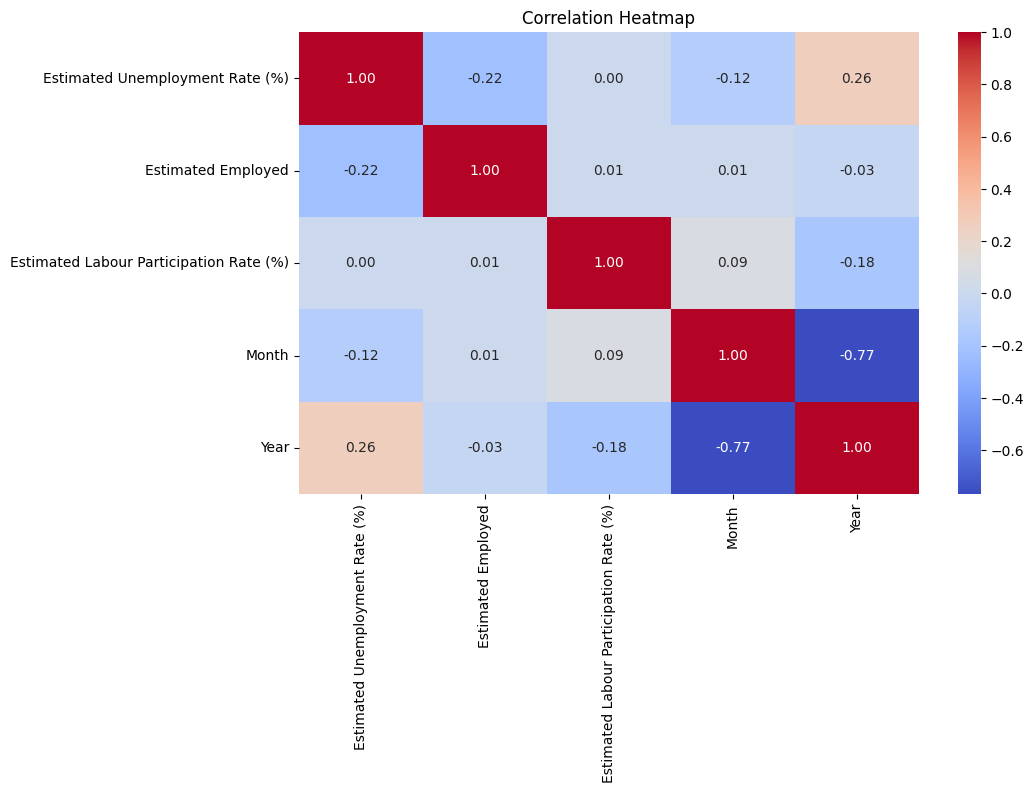

In [13]:
plt.figure(figsize=(10,6))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [14]:
pre_covid = df[df['Date'] < '2020-03-01']['Estimated Unemployment Rate (%)'].mean()

post_covid = df[df['Date'] >= '2020-03-01']['Estimated Unemployment Rate (%)'].mean()

print("Pre-COVID Average:", pre_covid)
print("Post-COVID Average:", post_covid)

Pre-COVID Average: 9.509533582089553
Post-COVID Average: 17.774362745098042


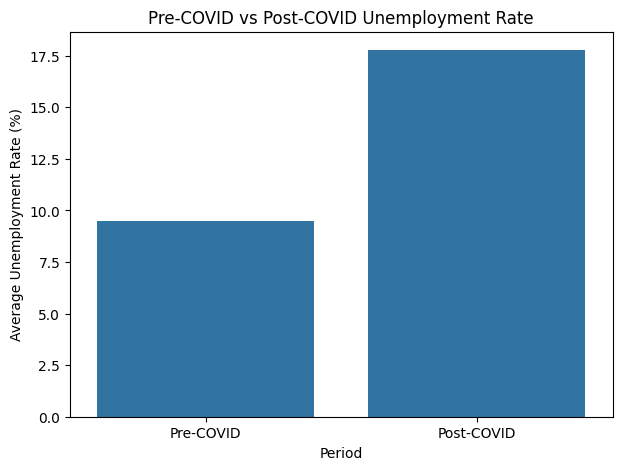

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

covid_comparison = pd.DataFrame({
    'Period': ['Pre-COVID', 'Post-COVID'],
    'Average Unemployment Rate': [pre_covid, post_covid]
})

plt.figure(figsize=(7,5))

sns.barplot(
    data=covid_comparison,
    x='Period',
    y='Average Unemployment Rate'
)

plt.title('Pre-COVID vs Post-COVID Unemployment Rate')
plt.ylabel('Average Unemployment Rate (%)')
plt.show()

## Final Observations

1. Unemployment rates vary across different states in India.
2. Monthly unemployment rates show changes over time.
3. The selected states have different unemployment trends.
4. The heatmap shows relationships between numerical variables.
5. The average unemployment rate differs between the pre-COVID and post-COVID periods.

## Conclusion

This project analyzes unemployment trends in India using Python. Pandas was used for data cleaning and analysis, while Matplotlib and Seaborn were used for data visualization. The analysis helps us understand changes in unemployment rates across states and time periods.